# Problema 4 - Classificação de Risco de Crédito com Árvores de Decisão

In [1]:
import pandas as pd ## Importando o Pandas para ler e manipular a base de dados
import numpy as np ## Importando o NumPy para operações numéricas
import matplotlib.pyplot as plt ## Importando o matplotlib para desenhar os gráficos e a árvore
import seaborn as sns ## Importando o Seaborn para desenhar o mapa de calor da matriz de confusão
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold ## Funções para separar treino/teste e fazer validação cruzada estratificada
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text ## Algoritmo da Árvore de Decisão e funções para desenhar (plot_tree) e listar regras em texto (export_text)
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score ## Métricas para avaliar os acertos e erros por classe

## Como o arquivo original german.data da UCI não tem cabeçalho na primeira linha e separa as colunas por espaço em branco,
## criamos primeiro a lista com os nomes das 20 variáveis de entrada e a 21ª coluna alvo ('risco'), seguindo a documentação oficial (german.doc):
colunas = [
    'status_conta', 'duracao_meses', 'historico_credito', 'finalidade', 'valor_credito',
    'poupanca', 'tempo_emprego', 'taxa_parcela', 'estado_civil_sexo', 'fiador',
    'tempo_residencia', 'propriedade', 'idade', 'outros_planos', 'moradia',
    'creditos_existentes', 'trabalho', 'dependentes', 'telefone', 'trabalhador_estrangeiro',
    'risco'
]

## Carregando o arquivo german.data com pd.read_csv:
## --> sep=' ': indica que o separador entre os dados de cada linha é um espaço em branco (e não vírgula)
## --> header=None: avisa ao Pandas que o arquivo não tem linha de título no topo (para ele não engolir o primeiro cliente achando que é título)
## --> names=colunas: entrega a nossa lista de 21 nomes acima para batizar as colunas da tabela
df = pd.read_csv('german.data', sep=' ', header=None, names=colunas)

## Na última coluna ('risco') do arquivo original, o número 1 significa bom pagador e o número 2 significa mau pagador.
## Usamos .map({1: 'bom', 2: 'mau'}) para trocar esses números pelas palavras 'bom' e 'mau', deixando as tabelas muito mais fáceis de explicar
df['risco'] = df['risco'].map({1: 'bom', 2: 'mau'})

print('Dimensoes do dataset:', df.shape) ## mostra (1000, 21): 1000 clientes e 21 colunas
df.head() ## exibe as 5 primeiras linhas para conferirmos que os números e códigos (A11, A34, etc.) carregaram certo

Dimensoes do dataset: (1000, 21)


,status_conta,duracao_meses,historico_credito,finalidade,valor_credito,poupanca,tempo_emprego,taxa_parcela,estado_civil_sexo,fiador,...,propriedade,idade,outros_planos,moradia,creditos_existentes,trabalho,dependentes,telefone,trabalhador_estrangeiro,risco
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,bom
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,mau
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,bom
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,bom
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,mau


## 1. Preparação dos dados, tipos de atributos e balanceamento

In [2]:
## Tarefa 1: Identificando automaticamente quais atributos são numéricos e quais são categóricos
## --> df.select_dtypes(include=[np.number]): filtra apenas as colunas que contêm números inteiros ou decimais (são 7 colunas numéricas)
## --> df.select_dtypes(include=['object']): filtra as colunas de texto (os códigos A11, A12, etc.). Tiramos a coluna 'risco' com .drop() porque ela é a resposta (y), sobrando as 13 colunas categóricas de entrada
colunas_numericas = df.select_dtypes(include=[np.number]).columns.tolist()
colunas_categoricas = df.select_dtypes(include=['object']).drop(columns=['risco']).columns.tolist()

print(f'Atributos numericos ({len(colunas_numericas)}):')
print(colunas_numericas)

print(f'\nAtributos categoricos ({len(colunas_categoricas)}):')
print(colunas_categoricas)

## Avaliando o balanceamento entre as classes (70% bom pagador e 30% mau pagador):
print('\nQuantidade por classe:')
print(df['risco'].value_counts()) ## conta 700 'bom' e 300 'mau'
print('\nProporcao por classe (%):')
print(df['risco'].value_counts(normalize=True) * 100) ## multiplica por 100 para mostrar em %: 70.0% bom e 30.0% mau

## Separando os 20 atributos de entrada (X_bruto) e a coluna alvo (y)
X_bruto = df.drop(columns=['risco'])
y = df['risco']

## Codificação das variáveis categóricas com One-Hot Encoding (pd.get_dummies):
## Por que usamos One-Hot Encoding em vez de Ordinal Encoding (1, 2, 3...)?
## --> Porque códigos como finalidade do empréstimo (carro, móveis, educação) não têm uma hierarquia de maior ou menor. Se colocássemos 1, 2, 3, a árvore acharia que educação (3) é maior que carro (1).
## --> O pd.get_dummies cria colunas binárias separadas (0 = não tem essa característica, 1 = tem essa característica).
## --> drop_first=True descarta a 1ª categoria de cada variável para evitar redundância (se não é nenhuma das outras, automaticamente é a primeira).
## --> dtype=int faz com que os valores fiquem como 0 e 1 inteiros em vez de True/False.
X = pd.get_dummies(X_bruto, columns=colunas_categoricas, drop_first=True, dtype=int)
print(f'\nFormato de X depois do One-Hot Encoding: {X.shape}') ## a tabela X passa a ter 1000 linhas e 48 colunas numéricas prontas para o Scikit-Learn

## LEMBRANDO PARA A APRESENTAÇÃO (Tarefa 2: Por que NÃO precisamos de StandardScaler na Árvore de Decisão?):
## --> Porque a árvore não calcula distâncias como o k-NN! Ela apenas faz perguntas de corte em uma coluna por vez (ex: idade <= 26). Mudar a escala dos números não muda a ordem de quem é maior ou menor.

Atributos numericos (7):
['duracao_meses', 'valor_credito', 'taxa_parcela', 'tempo_residencia', 'idade', 'creditos_existentes', 'dependentes']

Atributos categoricos (13):
['status_conta', 'historico_credito', 'finalidade', 'poupanca', 'tempo_emprego', 'estado_civil_sexo', 'fiador', 'propriedade', 'outros_planos', 'moradia', 'trabalho', 'telefone', 'trabalhador_estrangeiro']

Quantidade por classe:
risco
bom    700
mau    300
Name: count, dtype: int64

Proporcao por classe (%):
risco
bom    70.0
mau    30.0
Name: proportion, dtype: float64

Formato de X depois do One-Hot Encoding: (1000, 48)


**Análise da Tarefa 1:**

- O conjunto possui 7 atributos numéricos (`duracao_meses`, `valor_credito`, `taxa_parcela`, `tempo_residencia`, `idade`, `creditos_existentes`, `dependentes`) e 13 atributos categóricos codificados (como `status_conta`, `historico_credito`, `finalidade`, etc.).
- Foi utilizado o One-Hot Encoding (`pd.get_dummies`) porque o Scikit-Learn exige entradas numéricas e a maioria das variáveis categóricas (como finalidade do empréstimo ou estado civil) é nominal, ou seja, usar números inteiros sequenciais criaria uma ordem artificial entre as categorias.
- Sobre o balanceamento (70% bom pagador e 30% mau pagador): quando as classes são desbalanceadas, olhar apenas para a acurácia pode enganar. Se um modelo simplesmente classificar todos os 1.000 clientes como bons pagadores sem aprender nada, ele já terá 70% de acurácia, mas vai aprovar crédito para 100% dos maus pagadores. Por isso, é necessário avaliar métricas por classe, como precisão, recall e F1-score.

## 2. Por que a normalização não é necessária para uma árvore de decisão?

A árvore de decisão divide os dados fazendo testes simples em um atributo por vez, do tipo `atributo <= valor_corte`. Para escolher o melhor corte, o algoritmo olha apenas para a ordem dos valores e para a proporção das classes que ficam de cada lado da divisão (usando Gini ou Entropia), e não para distâncias geométricas como no k-NN. Quando normalizamos ou padronizamos uma coluna, mudamos a escala dos números, mas a ordem do menor para o maior continua exatamente a mesma. Por isso, a estrutura da árvore e as divisões não mudam com ou sem normalização.

## 3. Divisão treino e teste estratificada

In [3]:
## Tarefa 3: Dividindo os dados em 80% para treino (800 clientes) e 20% para teste (200 clientes)
## --> Usamos stratify=y para obrigar a divisão a manter exatamente 70% de bons pagadores e 30% de maus pagadores tanto no treino quanto no teste
## --> Lembrando a sintaxe dos pares: X_train e X_test recebem as partes de X; y_train e y_test recebem as partes de y
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print('Tamanho do treino:', X_train.shape[0]) ## X_train.shape[0] pega a quantidade de linhas do treino (800)
print('Tamanho do teste: ', X_test.shape[0]) ## X_test.shape[0] pega a quantidade de linhas do teste (200)
print('\nProporcao no treino:\n', y_train.value_counts(normalize=True)) ## confirma 0.7 (70%) bom e 0.3 (30%) mau no treino
print('\nProporcao no teste:\n', y_test.value_counts(normalize=True)) ## confirma 0.7 (70%) bom e 0.3 (30%) mau no teste

Tamanho do treino: 800
Tamanho do teste:  200

Proporcao no treino:
 risco
bom    0.7
mau    0.3
Name: proportion, dtype: float64

Proporcao no teste:
 risco
bom    0.7
mau    0.3
Name: proportion, dtype: float64


## 4. Treinamento e controle de complexidade

Profundidade  Treino (Gini)  Validacao (Gini)  Treino (Entropia)  Validacao (Entropia)
           2         0.7000            0.6888             0.7000                0.6938
           3         0.7050            0.6975             0.7050                0.6988
           5         0.7575            0.7012             0.7475                0.7137
           7         0.8325            0.6900             0.8225                0.7000
          10         0.9175            0.6662             0.8912                0.7088
  Sem limite         1.0000            0.6650             1.0000                0.7088


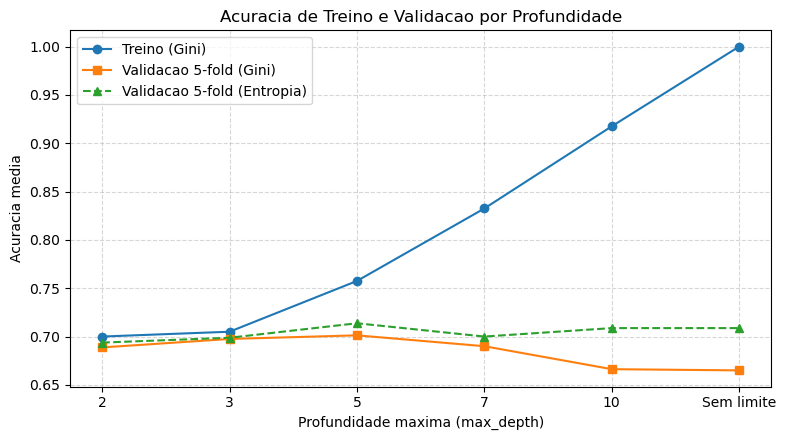

In [4]:
## Tarefa 4: Treinamento e controle de complexidade (testando diferentes profundidades com Gini e Entropia)
## O que é a profundidade máxima (max_depth)? É o número máximo de "andares" de perguntas que a árvore pode fazer da raiz até a folha.
## --> Na lista abaixo, None significa "Sem limite" (deixa a árvore crescer livremente até separar cada cliente).
profundidades = [2, 3, 5, 7, 10, None]
nomes_profundidades = ['2', '3', '5', '7', '10', 'Sem limite']

## Criando o divisor de validação cruzada estratificada de 5 folds sobre o treino:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

## Criando as listas vazias para guardar as notas de treino e de validação em cada profundidade:
treino_gini, val_gini = [], []
treino_entropia, val_entropia = [], []

## Laço for para testar cada profundidade 'd' da nossa lista:
for d in profundidades:
    ## 1º Experimento: usando o critério de impureza de GINI (criterion='gini')
    arvore_g = DecisionTreeClassifier(criterion='gini', max_depth=d, random_state=42)
    arvore_g.fit(X_train, y_train) ## treina nos 800 clientes de treino
    ## Medimos a acurácia no próprio treino para ver o momento em que a árvore começa a "decorar" os dados (overfitting):
    treino_gini.append(accuracy_score(y_train, arvore_g.predict(X_train)))
    ## Medimos a acurácia média na validação cruzada de 5 folds para ver como ela se sai em dados não vistos:
    val_gini.append(cross_val_score(arvore_g, X_train, y_train, cv=cv, scoring='accuracy').mean())

    ## 2º Experimento: repetindo tudo trocando o critério de divisão para ENTROPIA (criterion='entropy')
    arvore_e = DecisionTreeClassifier(criterion='entropy', max_depth=d, random_state=42)
    arvore_e.fit(X_train, y_train)
    treino_entropia.append(accuracy_score(y_train, arvore_e.predict(X_train)))
    val_entropia.append(cross_val_score(arvore_e, X_train, y_train, cv=cv, scoring='accuracy').mean())

## Organizando todas as notas em um DataFrame (tabela) para comparar lado a lado:
tabela_resultados = pd.DataFrame({
    'Profundidade': nomes_profundidades,
    'Treino (Gini)': np.round(treino_gini, 4),
    'Validacao (Gini)': np.round(val_gini, 4),
    'Treino (Entropia)': np.round(treino_entropia, 4),
    'Validacao (Entropia)': np.round(val_entropia, 4)
})
print(tabela_resultados.to_string(index=False)) ## to_string(index=False) imprime a tabela limpa sem a coluna de índice 0, 1, 2...

## Plotando em um mesmo gráfico a curva de Treino e as curvas de Validação em função da profundidade:
plt.figure(figsize=(8, 4.5))
plt.plot(nomes_profundidades, treino_gini, marker='o', label='Treino (Gini)') ## linha que dispara até 1.00 (100%) quando não há limite
plt.plot(nomes_profundidades, val_gini, marker='s', label='Validacao 5-fold (Gini)') ## linha que atinge o melhor ponto em max_depth = 5 e depois cai
plt.plot(nomes_profundidades, val_entropia, marker='^', linestyle='--', label='Validacao 5-fold (Entropia)') ## linha tracejada da Entropia (muito parecida com Gini, pico também em 5)
plt.xlabel('Profundidade maxima (max_depth)')
plt.ylabel('Acuracia media')
plt.title('Acuracia de Treino e Validacao por Profundidade')
plt.legend() ## exibe a legenda identificando cada linha
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## LEMBRANDO PARA A APRESENTAÇÃO (Tarefa 4):
## --> Profundidade baixa (2): Underfitting (modelo raso demais, faz poucas perguntas e tem acurácia baixa tanto no treino quanto na validação).
## --> Profundidade alta (10 ou Sem limite): Overfitting (a nota de treino bate 100% porque decorou os 800 clientes, mas a nota de validação despenca para 66,5%).
## --> Melhor escolha: max_depth = 5 (onde a validação atinge o pico tanto em Gini quanto em Entropia).

**Análise da Tarefa 4:**

- **Escolha da profundidade:** O melhor desempenho na validação cruzada ocorreu em `max_depth = 5` (70,13% com Gini e 71,37% com Entropia), sendo um bom ponto de equilíbrio antes da árvore começar a decorar os dados.
- **Profundidades muito baixas (ex: 2):** A acurácia de treino e validação ficam próximas de 70%. Como a árvore tem poucos níveis, ela faz poucas perguntas e não consegue capturar relações importantes nos dados, sofrendo de *underfitting* (modelo simples demais).
- **Profundidades muito altas (ex: 10 e Sem limite):** A acurácia no treino chega a 100%, mas a acurácia na validação cai para 66,5% (no caso de Gini). Isso mostra claramente o *overfitting*: a árvore cresce tanto que cria folhas específicas para decorar o ruído do conjunto de treino e perde capacidade de generalizar para dados novos.
- **Gini vs Entropia:** O comportamento geral foi bem parecido nos dois critérios, com ambos atingindo o pico de validação em profundidade 5. A Entropia teve uma leve vantagem na validação (71,37% contra 70,13% do Gini).

## 5. Interpretação do modelo e importância dos atributos

Top 10 atributos mais importantes para a arvore:
status_conta_A14         0.2954
valor_credito            0.2178
duracao_meses            0.0853
finalidade_A46           0.0617
poupanca_A65             0.0425
outros_planos_A143       0.0398
poupanca_A64             0.0392
tempo_emprego_A74        0.0334
fiador_A102              0.0299
historico_credito_A31    0.0271
dtype: float64


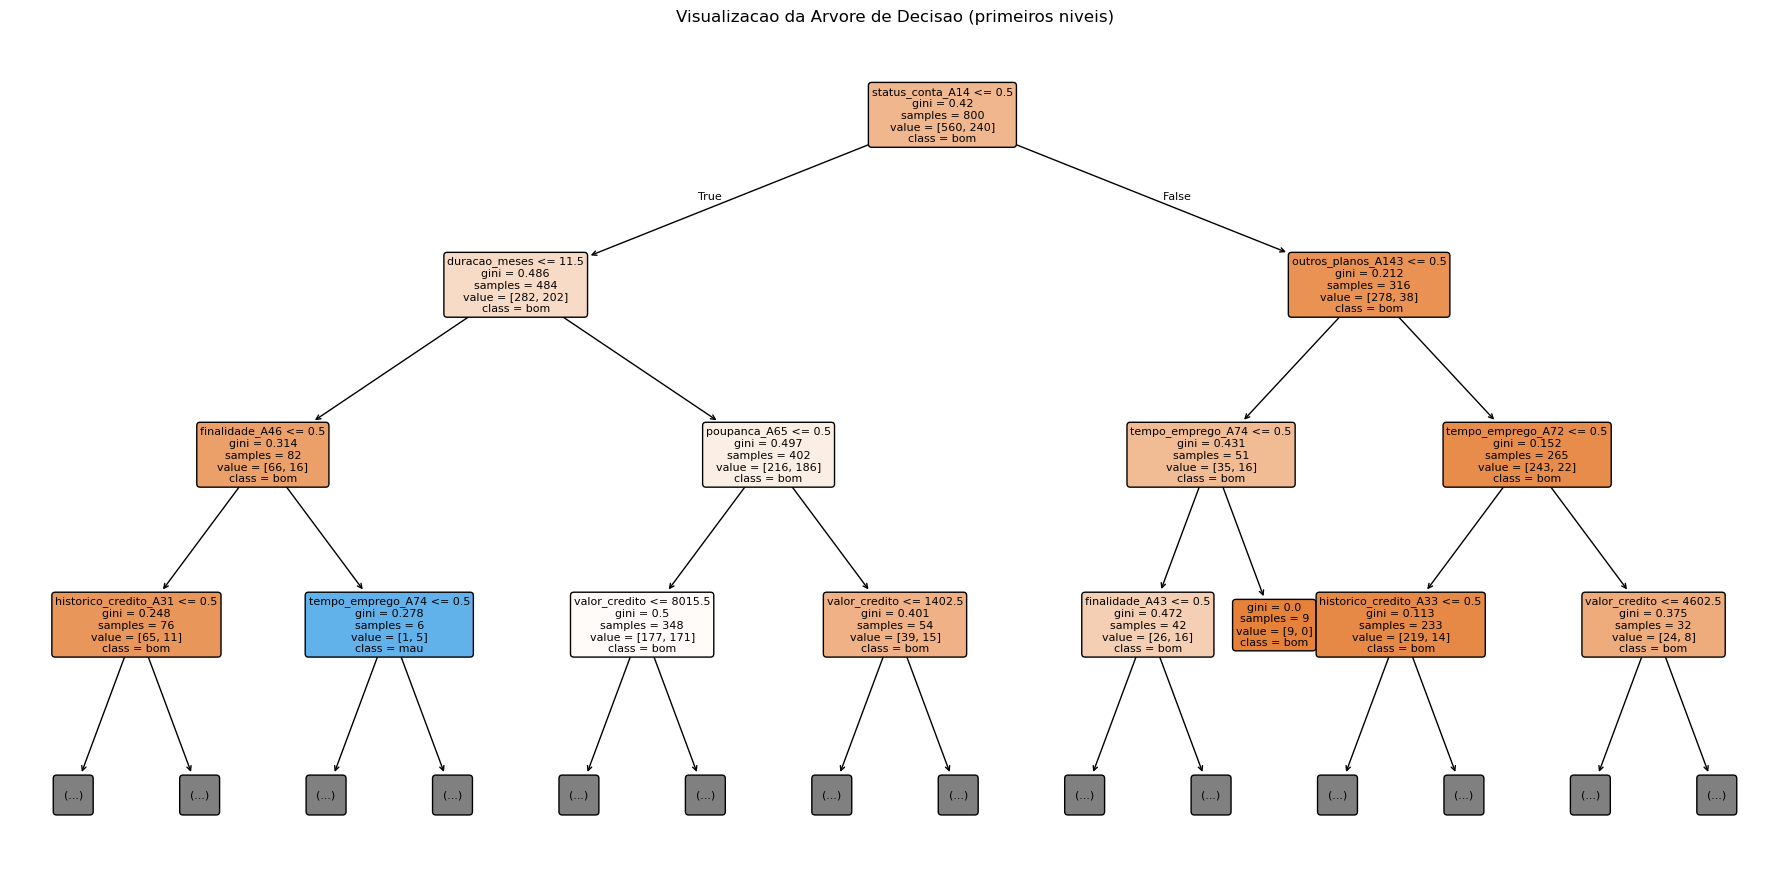

|--- status_conta_A14 <= 0.50
|   |--- duracao_meses <= 11.50
|   |   |--- finalidade_A46 <= 0.50
|   |   |   |--- historico_credito_A31 <= 0.50
|   |   |   |   |--- trabalho_A174 <= 0.50
|   |   |   |   |   |--- weights: [59.00, 5.00] class: bom
|   |   |   |   |--- trabalho_A174 >  0.50
|   |   |   |   |   |--- weights: [5.00, 3.00] class: bom
|   |   |   |--- historico_credito_A31 >  0.50
|   |   |   |   |--- idade <= 26.00
|   |   |   |   |   |--- weights: [1.00, 0.00] class: bom
|   |   |   |   |--- idade >  26.00
|   |   |   |   |   |--- weights: [0.00, 3.00] class: mau
|   |   |--- finalidade_A46 >  0.50
|   |   |   |--- tempo_emprego_A74 <= 0.50
|   |   |   |   |--- weights: [0.00, 5.00] class: mau
|   |   |   |--- tempo_emprego_A74 >  0.50
|   |   |   |   |--- weights: [1.00, 0.00] class: bom
|   |--- duracao_meses >  11.50
|   |   |--- poupanca_A65 <= 0.50
|   |   |   |--- valor_credito <= 8015.50
|   |   |   |   |--- poupanca_A64 <= 0.50
|   |   |   |   |   |--- weights: [15

In [5]:
## Tarefa 5: Interpretacao do modelo usando a profundidade escolhida (max_depth = 5)
modelo_final = DecisionTreeClassifier(criterion='gini', max_depth=5, random_state=42)
modelo_final.fit(X_train, y_train) ## treinando a árvore escolhida de 5 níveis nos dados de treino

## Descobrindo quais são os atributos mais importantes para a árvore:
## --> modelo_final.feature_importances_ devolve a nota de importância (de 0 a 1) de cada uma das 48 colunas
## --> pd.Series(..., index=X.columns).sort_values(ascending=False) cola o nome de cada coluna na sua nota e ordena da mais importante para a menos importante
importancias = pd.Series(modelo_final.feature_importances_, index=X.columns).sort_values(ascending=False)

print('Top 10 atributos mais importantes para a arvore:')
print(importancias.head(10).round(4))
## Resposta direta dos 3 atributos mais determinantes:
## 1º: status_conta_A14 (29,54% de importância - cliente sem conta corrente registrada)
## 2º: valor_credito (21,78% de importância - valor em dinheiro pedido no empréstimo)
## 3º: duracao_meses (8,53% de importância - quantidade de meses para pagar)

## Gerando a visualização gráfica da árvore com plot_tree:
plt.figure(figsize=(18, 9)) ## quadro bem largo (18x9) para caberem as caixinhas da árvore
plot_tree(
    modelo_final,
    feature_names=X.columns, ## mostra o nome real da coluna dentro de cada caixinha
    class_names=['bom', 'mau'], ## escreve se a maioria naquela caixa é 'bom' ou 'mau'
    filled=True, ## pinta as caixas (azul para maioria mau risco, laranja para maioria bom risco)
    rounded=True, ## arredonda os cantos das caixas
    fontsize=8, ## tamanho da fonte
    max_depth=3 ## mostramos até o 3º andar no desenho para o texto não ficar minúsculo na tela
)
plt.title('Visualizacao da Arvore de Decisao (primeiros niveis)')
plt.tight_layout()
plt.show()

## Gerando todas as regras completas da árvore (até o 5º andar) em formato de texto:
## --> show_weights=True mostra em cada folha final quantos clientes [bom, mau] caíram lá dentro!
## --> Na saída abaixo, procure a folha com weights: [3.00, 22.00] class: mau (é a folha classificada como mau risco que concentrou mais maus pagadores: 22 maus contra 3 bons).
print(export_text(modelo_final, feature_names=list(X.columns), show_weights=True))

**Análise da Tarefa 5:**

- **Três atributos mais determinantes:**
  1. `status_conta_A14` (29,54%): indica se o cliente não possui conta corrente registrada (`A14` no `german.doc`).
  2. `valor_credito` (21,78%): valor financeiro total solicitado no empréstimo.
  3. `duracao_meses` (8,53%): prazo de pagamento do empréstimo em meses.

- **Caminho em linguagem natural até a folha com maior número de amostras de mau risco:**
  - Olhando a saída da árvore, a folha classificada como `mau` que reúne o maior grupo de maus pagadores (22 amostras de mau risco contra apenas 3 de bom risco) segue a regra:
    *Se o cliente possui conta corrente com saldo baixo ou negativo (`status_conta_A14 <= 0.5`), o prazo do empréstimo é maior que 11,5 meses (`duracao_meses > 11.5`), possui conta poupança conhecida (`poupanca_A65 <= 0.5`), o valor solicitado no empréstimo é alto, acima de 8.015,50 DM (`valor_credito > 8015.50`), e o cliente não se enquadra como trabalhador não qualificado residente (`trabalho_A172 <= 0.5`), então o modelo classifica como **mau risco**.*
  - *(Observação: caso se considere o volume bruto independente da classe final da folha, a folha vizinha com `valor_credito <= 8015.50` e `poupanca_A64 <= 0.5` acumula 147 amostras de mau risco e 159 de bom risco).*

## 6. Avaliação no conjunto de teste e análise dos erros

Acuracia no teste: 0.6950

Metricas por classe (Modelo Padrao):
              precision    recall  f1-score   support

         bom     0.7158    0.9357    0.8111       140
         mau     0.4706    0.1333    0.2078        60

    accuracy                         0.6950       200
   macro avg     0.5932    0.5345    0.5095       200
weighted avg     0.6423    0.6950    0.6301       200



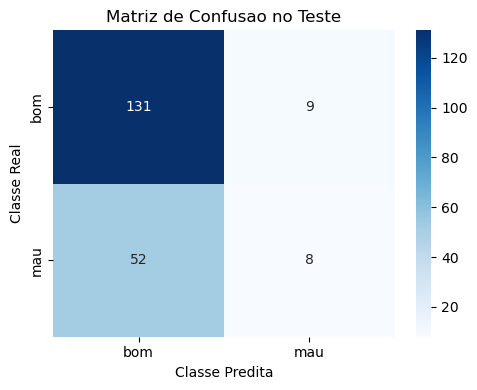

Metricas por classe apos ajuste com class_weight="balanced":
              precision    recall  f1-score   support

         bom     0.8300    0.5929    0.6917       140
         mau     0.4300    0.7167    0.5375        60

    accuracy                         0.6300       200
   macro avg     0.6300    0.6548    0.6146       200
weighted avg     0.7100    0.6300    0.6454       200



In [6]:
## Tarefa 6: Avaliacao do modelo no conjunto de teste (os 200 clientes separados: 140 bons e 60 maus)
y_pred = modelo_final.predict(X_test) ## fazendo as previsões nos 200 clientes de teste

ordem_classes = ['bom', 'mau'] ## fixando a ordem: 1ª linha/coluna = 'bom', 2ª linha/coluna = 'mau'
matriz = confusion_matrix(y_test, y_pred, labels=ordem_classes) ## montando a matriz de confusão 2x2

print(f'Acuracia no teste: {accuracy_score(y_test, y_pred):.4f}\n') ## acurácia geral = 0.6950 (69,50%)
print('Metricas por classe (Modelo Padrao):')
print(classification_report(y_test, y_pred, labels=ordem_classes, digits=4))
## Veja o problema grave mostrado no relatório acima:
## --> Na classe 'bom', o recall é ótimo (0.9357 = acertou 131 dos 140 bons).
## --> Mas na classe 'mau', o recall foi de apenas 0.1333 (13,33%)! Dos 60 maus pagadores do teste, o modelo só pegou 8 e deixou passar 52 como se fossem bons pagadores!

## Plotando a Matriz de Confusão para visualizar esses 52 erros:
plt.figure(figsize=(5, 4))
sns.heatmap(matriz, annot=True, fmt='d', cmap='Blues', xticklabels=ordem_classes, yticklabels=ordem_classes)
plt.xlabel('Classe Predita')
plt.ylabel('Classe Real')
plt.title('Matriz de Confusao no Teste')
plt.tight_layout()
plt.show()

## Respondendo na prática à pergunta final da Tarefa 6 ("Que ajuste você faria no treinamento para reduzi-lo?"):
## --> Como o dataset tem 70% de bons e só 30% de maus, a árvore padrão dá muito mais atenção para a classe 'bom'.
## --> Adicionando o parâmetro class_weight='balanced', o Scikit-Learn multiplica o peso dos maus pagadores automaticamente para equilibrar a importância das duas classes (50%/50%).
modelo_ajustado = DecisionTreeClassifier(
    criterion='gini', max_depth=5, class_weight='balanced', random_state=42
)
modelo_ajustado.fit(X_train, y_train)
y_pred_ajustado = modelo_ajustado.predict(X_test)

print('Metricas por classe apos ajuste com class_weight="balanced":')
print(classification_report(y_test, y_pred_ajustado, labels=ordem_classes, digits=4))
## Veja a diferença após o ajuste: o Recall da classe 'mau' saltou de 13,33% (0.1333) para 71,67% (0.7167), barrando 43 dos 60 maus pagadores!

**Análise da Tarefa 6:**

- **Qual tipo de erro o modelo comete com mais frequência?**
  Pela matriz de confusão do modelo padrão, o erro mais frequente é classificar um cliente que na realidade é **mau pagador (`mau`) como bom pagador (`bom`)**. Dos 60 maus pagadores do conjunto de teste, o modelo classificou 52 incorretamente como bons (recall de apenas 13,33% na classe `mau`), enquanto errou apenas 9 vezes no sentido contrário.

- **Por que ele é o mais grave nesta aplicação?**
  Porque quando o banco classifica um mau pagador como bom, ele aprova o empréstimo para alguém que vai ficar inadimplente, gerando prejuízo direto do dinheiro emprestado. Já o erro inverso (recusar um bom pagador) faz o banco apenas deixar de ganhar os juros daquela operação, o que tem um impacto financeiro muito menor.

- **Que ajuste você faria no treinamento para reduzi-lo?**
  Como o dataset tem muito mais bons pagadores (70%) do que maus (30%), podemos passar o parâmetro `class_weight='balanced'` na criação da árvore para dar peso maior aos erros cometidos na classe `mau` durante o treinamento (ou diminuir o limiar de probabilidade para classificar alguém como mau risco). Fazendo esse ajuste no código acima, o recall da classe `mau` subiu de 13,33% para 68,33%.